# Відновлення зашумлених зображень за допомогою автоенкодера

Семестровий проєкт із нейронних мереж. Реалізація на PyTorch, навчання на GPU в Kaggle, набір даних DIV2K.

Працюємо з кольоровими зображеннями. До чистої фотографії $x\in[0,1]^{3\times H\times W}$ додаємо гаусівський шум $\varepsilon\sim\mathcal N(0,(\sigma/255)^2)$:

$$y=\operatorname{clip}(x+\varepsilon,0,1),\qquad \hat{x}=f_\theta(y).$$

Модель отримує $y$ і навчається відновлювати $x$. Функція втрат — MSE. Якість перевіряємо за PSNR, SSIM, MSE та MAE. Додатково порівнюємо час навчання й використання відеопам'яті.

У роботі є дві архітектури — CDAE та Skip-CDAE, експеримент зі швидкістю навчання (`learning rate`) і два прості орієнтири: зашумлений вхід без обробки та Gaussian Blur.

**Дані.** Із 800 офіційних тренувальних фотографій DIV2K беремо 720 для навчання та 80 для валідації. Ще 100 фотографій з офіційного `DIV2K_valid_HR` використовуємо тільки для фінального тесту. Це власний поділ роботи, а не офіційний результат DIV2K benchmark.

**Перед запуском:** додати в `Add Input` папки `DIV2K_train_HR` і `DIV2K_valid_HR` (або архіви з ними), а в налаштуваннях Notebook увімкнути GPU. Основні параметри змінюються в наступній кодовій комірці.

## 1. Налаштування запуску

Стандартний запуск складається з трьох експериментів: CDAE, Skip-CDAE та Skip-CDAE зі зменшеним learning rate. Максимум — 25 епох по 3000 фрагментів розміром 96×96; якщо валідаційна якість перестане зростати, навчання зупиниться раніше.

Окремими перемикачами можна ввімкнути експерименти з розміром фрагмента, рівнем шуму, кількістю фотографій і випадковими ініціалізаціями.

In [4]:
from pathlib import Path
import os, sys, json, math, random, time, platform, hashlib, gc, shutil, subprocess, zipfile
from datetime import datetime, timezone
from dataclasses import dataclass, asdict, replace
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from skimage.metrics import structural_similarity
import cv2

# Основні параметри запуску
DATA_ROOT = Path('/kaggle/input')  # шукати дані серед Kaggle inputs
TRAIN_DIR = None                  # за потреби вказати папку train
VALID_DIR = None                  # за потреби вказати папку valid
OUTPUT = Path('/kaggle/working/denoising_autoencoder')

RUN_EXTENDED = False               # crop 128 і різні рівні шуму
RUN_STABILITY = True              # повторні запуски з іншими seeds
RUN_DATA_ABLATION = False          # порівняння розміру train-вибірки
RUN_FINAL_TEST = True              # фінальна оцінка на 100 фото

SEED = 42
PATCH_SIZE = 96
PATCHES_PER_EPOCH = 3000
BATCH_SIZE = 32
MAX_EPOCHS = 25
PATIENCE = 6
NUM_WORKERS = 2                  # можна поставити 0 при помилках DataLoader
AMP = True                        # змішана точність на GPU
USE_RAM_CACHE = True              # читати train RGB у RAM один раз
VAL_CROPS_PER_IMAGE = 4
TEST_SIGMAS = (15, 25, 50)

OUTPUT.mkdir(parents=True, exist_ok=True)
(OUTPUT / 'figures').mkdir(exist_ok=True)
(OUTPUT / 'runs').mkdir(exist_ok=True)
(OUTPUT / 'manifests').mkdir(exist_ok=True)

assert torch.cuda.is_available(), 'GPU не знайдено. У Kaggle: Settings → Accelerator → GPU.'
DEVICE = torch.device('cuda:0')
GPU_NAME = torch.cuda.get_device_name(0)
torch.backends.cudnn.benchmark = True  # швидше навчання; точна повторюваність не гарантована
cv2.setNumThreads(0)

def seed_all(seed):
    random.seed(int(seed)); np.random.seed(int(seed)); torch.manual_seed(int(seed))
    torch.cuda.manual_seed_all(int(seed))

seed_all(SEED)

ENV = {
    'utc': datetime.now(timezone.utc).isoformat(), 'python': sys.version,
    'torch': torch.__version__, 'numpy': np.__version__, 'pandas': pd.__version__,
    'opencv': cv2.__version__, 'gpu': GPU_NAME,
    'cuda': torch.version.cuda, 'platform': platform.platform(),
    'gpu_memory_gb': round(torch.cuda.get_device_properties(0).total_memory/2**30, 2),
    'kaggle_input_root': str(DATA_ROOT), 'seed': SEED,
    'amp_requested': AMP, 'strict_determinism': False,
}
(OUTPUT/'environment.json').write_text(json.dumps(ENV, ensure_ascii=False, indent=2), encoding='utf-8')
print('GPU:', GPU_NAME, ' | GPU RAM:', ENV['gpu_memory_gb'], 'GiB | Torch:', torch.__version__)
print('Файли зберігатимуться:', OUTPUT)

GPU: Tesla T4  | GPU RAM: 14.56 GiB | Torch: 2.11.0+cu130
Файли зберігатимуться: /kaggle/working/denoising_autoencoder


## 2. Дані DIV2K

Знаходимо `DIV2K_train_HR` і `DIV2K_valid_HR`, перевіряємо кількість і розміри фотографій та зберігаємо поділ за ідентифікаторами зображень. Якщо набір додано як ZIP, він буде розпакований у робочу папку Kaggle. Файли з низькою роздільністю (`LR`) тут не потрібні.

In [5]:
import re
PATTERN = re.compile(r'^([0-9]{4})\.(png|jpg|jpeg)$', re.I)

def image_files(directory):
    d = Path(directory)
    return sorted(p for p in d.iterdir() if p.is_file() and PATTERN.match(p.name))

def locate_hr_dir(root, canonical_name, explicit=None):
    if explicit is not None:
        p = Path(explicit)
        if not p.is_dir(): raise FileNotFoundError(f'Неправильний шлях: {p}')
        return p
    dirs = [p for p in Path(root).rglob(canonical_name) if p.is_dir()]
    if not dirs:
        zips = [p for p in Path(root).rglob(canonical_name+'.zip') if p.is_file()]
        if zips:
            destination = OUTPUT/'unpacked'
            destination.mkdir(exist_ok=True)
            for archive in zips[:1]:
                print('Розпакування', archive.name)
                with zipfile.ZipFile(archive) as z:
                    for info in z.infolist():
                        resolved = (destination/info.filename).resolve()
                        if not resolved.is_relative_to(destination.resolve()):
                            raise ValueError('Небезпечний ZIP шлях')
                    z.extractall(destination)
            dirs = [p for p in destination.rglob(canonical_name) if p.is_dir()]
    if not dirs:
        raise FileNotFoundError(
            f'Не знайдено {canonical_name} в {root}. '
            'Натисніть Add Input, додайте DIV2K HR train та validation, або задайте TRAIN_DIR/VALID_DIR.'
        )
    # Якщо папок кілька, беремо ту, де найбільше відповідних файлів.
    return max(dirs, key=lambda d: len(image_files(d)))

train_dir = locate_hr_dir(DATA_ROOT, 'DIV2K_train_HR', TRAIN_DIR)
valid_dir = locate_hr_dir(DATA_ROOT, 'DIV2K_valid_HR', VALID_DIR)
train_all = image_files(train_dir)
test_all = image_files(valid_dir)
assert len(train_all) == 800, f'Очікується 800 train HR фотографій, отримано {len(train_all)} у {train_dir}'
assert len(test_all) == 100, f'Очікується 100 valid HR фотографій, отримано {len(test_all)} у {valid_dir}'
train_ids = [p.stem for p in train_all]
test_ids = [p.stem for p in test_all]
assert len(set(train_ids)) == 800 and len(set(test_ids)) == 100
assert set(train_ids).isdisjoint(test_ids), 'Data leakage: ID train і test перетинаються'
assert set(train_ids) == {f'{i:04d}' for i in range(1,801)}, 'Неправильний train HR split'
assert set(test_ids) == {f'{i:04d}' for i in range(801,901)}, 'Неправильний DIV2K valid HR split'

idx = np.random.default_rng(SEED).permutation(800)
train_paths = [train_all[i] for i in idx[:720]]
val_paths = [train_all[i] for i in idx[720:]]
test_paths = test_all
assert len({p.stem for p in train_paths} & {p.stem for p in val_paths}) == 0
for name, paths in [('train',train_paths),('val',val_paths),('test',test_paths)]:
    (OUTPUT/'manifests'/f'{name}.txt').write_text('\n'.join(p.stem for p in paths)+'\n', encoding='utf-8')

# Перевіряємо, чи всі зображення відкриваються.
print('Перевірка читабельності та розмірів 900 фото...')
heights, widths = [], []
for p in tqdm(train_all+test_all, desc='Checking DIV2K'):
    try:
        with Image.open(p) as im:
            im.verify()
        with Image.open(p) as im:
            w,h=im.size
            assert w>=PATCH_SIZE and h>=PATCH_SIZE
            widths.append(w); heights.append(h)
    except Exception as e:
        raise RuntimeError(f'Пошкоджене або занадто мале зображення {p}: {e}') from e

split_payload = {'seed':SEED,'source_train':str(train_dir),'source_valid':str(valid_dir),
                 'train_ids':[p.stem for p in train_paths], 'val_ids':[p.stem for p in val_paths],
                 'test_ids':[p.stem for p in test_paths]}
split_hash = hashlib.sha256(json.dumps({k:v for k,v in split_payload.items() if not k.startswith('source_')},sort_keys=True).encode()).hexdigest()
split_payload['split_sha256']=split_hash
(OUTPUT/'manifests'/'split.json').write_text(json.dumps(split_payload,indent=2,ensure_ascii=False),encoding='utf-8')
print('DIV2K OK | train 720 | val 80 | held-out test 100')
print('Розміри (W,H):', (min(widths),max(widths)), (min(heights),max(heights)))
print('Dataset:',train_dir, '|',valid_dir)
print('Split SHA256:',split_hash)

Перевірка читабельності та розмірів 900 фото...


Checking DIV2K:   0%|          | 0/900 [00:00<?, ?it/s]

DIV2K OK | train 720 | val 80 | held-out test 100
Розміри (W,H): (1116, 2040) (648, 2040)
Dataset: /kaggle/input/datasets/joe1995/div2k-dataset/DIV2K_train_HR/DIV2K_train_HR | /kaggle/input/datasets/joe1995/div2k-dataset/DIV2K_valid_HR/DIV2K_valid_HR
Split SHA256: 1ff30a05f828ca39c8d477b2963da3d14951b9b1e9ed55effc47c40371a10f58


## 3. Навчальні фрагменти

За замовчуванням зчитуємо чисті RGB-фотографії в оперативну пам'ять один раз, щоб не відкривати великі PNG на кожному кроці. Якщо пам'яті не вистачає, параметр `USE_RAM_CACHE` можна вимкнути.

Для навчання на кожній епосі вибираються нові фрагменти, а шум додається вже на GPU. При цьому кожна з 720 навчальних фотографій дає щонайменше один фрагмент за епоху. Валідаційні 320 фрагментів і шум для них фіксовані: так можна порівнювати різні моделі на тих самих прикладах.

In [7]:
from multiprocessing import Value

def load_rgb(path):
    with Image.open(path) as img:
        return np.array(img.convert('RGB'), dtype=np.uint8)

print('Читання clean фотографій у пам\'ять (один раз)...')
t0 = time.perf_counter()
train_images = [load_rgb(p) for p in tqdm(train_paths, desc='Train RAM')] if USE_RAM_CACHE else None
val_images = [load_rgb(p) for p in tqdm(val_paths, desc='Val RAM')]
ram_gb = (sum(a.nbytes for a in (train_images or []))+sum(a.nbytes for a in val_images)) / (2**30)
print(f'Підготовка: {time.perf_counter()-t0:.1f} c | обсяг RGB кешу {ram_gb:.2f} GiB')

class TrainPatches(Dataset):
    def __init__(self, paths, images=None, size=96, n_samples=3000, seed=42):
        self.paths=list(paths); self.images=images; self.size=int(size)
        self.n_samples=int(n_samples); self.seed=int(seed)
        self.epoch=Value('i', 0)
        if self.n_samples < len(self.paths):
            raise ValueError('samples_per_epoch має бути >= кількості train фото')

    def __len__(self): return self.n_samples
    def set_epoch(self, epoch):
        with self.epoch.get_lock(): self.epoch.value=int(epoch)

    def __getitem__(self, idx):
        ep=int(self.epoch.value)
        rng=np.random.default_rng(self.seed+ep*1000003+int(idx)*7919)
        if idx < len(self.paths):
            # Перестановка індексів: 131 взаємно просте з 720.
            im_index=(131*int(idx)+self.seed+ep*43)%len(self.paths)
        else:
            im_index=int(rng.integers(0,len(self.paths)))
        img=self.images[im_index] if self.images is not None else load_rgb(self.paths[im_index])
        h,w=img.shape[:2]; s=self.size
        assert h>=s and w>=s, f'Зображення замале: {self.paths[im_index]}'
        top=int(rng.integers(0,h-s+1)); left=int(rng.integers(0,w-s+1))
        crop=img[top:top+s,left:left+s]
        if rng.random()<0.5: crop=np.flip(crop,axis=0)
        if rng.random()<0.5: crop=np.flip(crop,axis=1)
        crop=np.rot90(crop,k=int(rng.integers(0,4)))
        clean=torch.from_numpy(np.ascontiguousarray(crop.transpose(2,0,1))).float().div_(255)
        return clean

def make_validation_arrays(images, paths, patch_size, n_crops=4, sigma=25, seed=2026):
    clean_list, noisy_list, records=[],[],[]
    for image_index,(img,p) in enumerate(zip(images,paths)):
        h,w=img.shape[:2]
        for k in range(n_crops):
            sample_id=image_index*n_crops+k
            rng=np.random.default_rng(seed+sample_id*11939)
            top=int(rng.integers(0,h-patch_size+1)); left=int(rng.integers(0,w-patch_size+1))
            crop=img[top:top+patch_size,left:left+patch_size].astype(np.float32)/255.0
            noise_rng=np.random.default_rng(seed+sample_id*123457+9)
            noisy=np.clip(crop+noise_rng.normal(0,sigma/255.0,crop.shape).astype(np.float32),0,1)
            clean_list.append(torch.from_numpy(crop.transpose(2,0,1).copy()))
            noisy_list.append(torch.from_numpy(noisy.transpose(2,0,1).copy()))
            records.append({'id':p.stem,'crop':k,'top':top,'left':left,
                            'patch_size':patch_size,'sigma_255':sigma,
                            'noise_seed':seed+sample_id*123457+9})
    return torch.stack(noisy_list),torch.stack(clean_list),records

val_noisy,val_clean,val_records=make_validation_arrays(val_images,val_paths,PATCH_SIZE,
                                             VAL_CROPS_PER_IMAGE,25,2026)
(OUTPUT/'manifests'/'validation_crops.json').write_text(json.dumps(val_records,indent=2),encoding='utf-8')
print('Val data:',tuple(val_noisy.shape),'| фіксовані шум і координати crop')

Читання clean фотографій у пам'ять (один раз)...


Train RAM:   0%|          | 0/720 [00:00<?, ?it/s]

Val RAM:   0%|          | 0/80 [00:00<?, ?it/s]

Підготовка: 79.5 c | обсяг RGB кешу 6.23 GiB
Val data: (320, 3, 96, 96) | фіксовані шум і координати crop


## 4. Архітектури CDAE та Skip-CDAE

Обидві моделі мають два рівні зменшення роздільності, bottleneck і декодер із bilinear upsampling. У Skip-CDAE додано зв'язки між відповідними рівнями енкодера та декодера; для них використано додавання ознак, а не конкатенацію.

Моделі не містять повнозв'язних шарів, тому можуть обробляти зображення різного розміру. Перед передаванням у мережу висота й ширина доповнюються до кратності чотирьом, а після відновлення зайві пікселі прибираються.

In [8]:
class ConvAct(nn.Sequential):
    def __init__(self, c_in, c_out, stride=1):
        super().__init__(nn.Conv2d(c_in,c_out,3,stride=stride,padding=1),nn.ReLU(inplace=True))

class CDAE(nn.Module):
    def __init__(self, skip=False):
        super().__init__()
        self.use_skip=bool(skip)
        self.enc1=nn.Sequential(ConvAct(3,32),ConvAct(32,32))
        self.down1=ConvAct(32,64,stride=2)
        self.enc2=ConvAct(64,64)
        self.down2=ConvAct(64,128,stride=2)
        self.bottleneck=ConvAct(128,128)
        self.up1=ConvAct(128,64)
        self.dec1=ConvAct(64,64)
        self.up2=ConvAct(64,32)
        self.output=nn.Sequential(nn.Conv2d(32,3,3,padding=1),nn.Sigmoid())

    def forward(self,x):
        h,w=x.shape[-2:]
        pad_h=(-h)%4; pad_w=(-w)%4
        if pad_h or pad_w:
            x=F.pad(x,(0,pad_w,0,pad_h),mode='replicate')
        e1=self.enc1(x)
        e2=self.enc2(self.down1(e1))
        z=self.bottleneck(self.down2(e2))
        u1=self.up1(F.interpolate(z,size=e2.shape[-2:],mode='bilinear',align_corners=False))
        if self.use_skip: u1=u1+e2
        u1=self.dec1(u1)
        u2=self.up2(F.interpolate(u1,size=e1.shape[-2:],mode='bilinear',align_corners=False))
        if self.use_skip: u2=u2+e1
        out=self.output(u2)
        return out[...,:h,:w]

def build_model(name):
    if name=='cdae': return CDAE(skip=False)
    if name=='skip_cdae': return CDAE(skip=True)
    raise ValueError('Невідома архітектура: '+name)

def param_count(model): return sum(p.numel() for p in model.parameters() if p.requires_grad)

for name in ['cdae','skip_cdae']:
    model=build_model(name)
    with torch.inference_mode():
        assert model(torch.rand(1,3,101,157)).shape == (1,3,101,157)
    print(name,':',f'{param_count(model):,}','trainable parameters')
    del model

cdae : 417,059 trainable parameters
skip_cdae : 417,059 trainable parameters


## 5. Метрики та перевірки

PSNR розраховуємо для кожного зображення окремо, після чого усереднюємо. Для SSIM використовуємо RGB-масиви в діапазоні `[0, 1]` і `data_range=1.0`. Результати порівнюються з чистою фотографією, а не із зашумленим входом.

Перед навчанням перевіряємо розміри виходу мережі, коректність метрик і базовий метод Gaussian Blur. Параметри фільтра підбираємо тільки на валідаційних даних.

In [9]:
def numpy_hwc(x):
    if torch.is_tensor(x):
        x=x.detach().float().cpu().numpy()
    if x.ndim==3 and x.shape[0]==3: return np.transpose(x,(1,2,0))
    if x.ndim==3 and x.shape[-1]==3: return x
    raise ValueError(f'Очікується RGB CHW або HWC, отримано {x.shape}')

def image_metrics(restored,clean):
    restored=np.clip(numpy_hwc(restored),0,1).astype(np.float32)
    clean=numpy_hwc(clean).astype(np.float32)
    err=restored-clean
    mse=float(np.mean(np.square(err),dtype=np.float64))
    mae=float(np.mean(np.abs(err),dtype=np.float64))
    psnr=float('inf') if mse==0 else float(-10*math.log10(mse))
    ssim=float(structural_similarity(clean,restored,data_range=1.0,channel_axis=-1))
    return {'mse':mse,'mae':mae,'psnr_db':psnr,'ssim':ssim}

def gaussian_filter(noisy,kernel=3,sigma=0.7):
    arr=numpy_hwc(noisy).astype(np.float32)
    return np.clip(cv2.GaussianBlur(arr,(kernel,kernel),sigmaX=sigma,sigmaY=sigma),0,1)

BLUR_CANDIDATES=[(3,0.5),(3,0.8),(3,1.2),(5,0.8),(5,1.2)]

def choose_gaussian_blur(noisy,clean):
    # Параметри фільтра підбираємо на val.
    results=[]
    for k,sigma in BLUR_CANDIDATES:
        scores=[]
        for a,b in zip(noisy,clean):
            scores.append(image_metrics(gaussian_filter(a,k,sigma),b)['psnr_db'])
        results.append({'kernel':k,'sigma':sigma,'val_psnr_db':float(np.mean(scores))})
    best=max(results,key=lambda r:r['val_psnr_db'])
    pd.DataFrame(results).to_csv(OUTPUT/'gaussian_filter_validation_search.csv',index=False)
    return best

# Перевірки працюють без тестових фотографій.
for name in ('cdae','skip_cdae'):
    m=build_model(name)
    for shape in [(1,3,96,96),(1,3,128,128),(1,3,101,157)]:
        with torch.inference_mode(): out=m(torch.rand(*shape))
        assert out.shape==shape and torch.isfinite(out).all()
        assert out.min()>=0 and out.max()<=1
    m.train()
    opt=torch.optim.Adam(m.parameters(),lr=0.001)
    inp=torch.rand(2,3,24,24)
    t=torch.rand(2,3,24,24)
    before=next(m.parameters()).detach().clone()
    loss=F.mse_loss(m(inp),t)
    loss.backward(); opt.step()
    assert torch.isfinite(loss).item() and not torch.equal(before,next(m.parameters()).detach())
    del m, opt
ref=torch.rand(3,24,24)
assert image_metrics(ref,ref)['psnr_db']==float('inf')
assert abs(image_metrics(ref,ref)['ssim']-1)<1e-5
assert image_metrics(torch.zeros(3,24,24),torch.ones(3,24,24))['psnr_db']==0
assert val_noisy.shape==val_clean.shape and not torch.equal(val_noisy,val_clean)
assert not ({p.stem for p in train_paths} & {p.stem for p in test_paths})
print('PASS: shapes, padding, finite output, backward/optimizer, PSNR/SSIM, split, val pairs')
blur_best=choose_gaussian_blur(val_noisy,val_clean)
print('Gaussian baseline підібрано за internal val:',blur_best)

PASS: shapes, padding, finite output, backward/optimizer, PSNR/SSIM, split, val pairs
Gaussian baseline підібрано за internal val: {'kernel': 5, 'sigma': 1.2, 'val_psnr_db': 27.97196119285933}


## 6. Навчання моделей

У всіх основних запусках використовується той самий порядок навчальних фрагментів і спосіб додавання шуму. Для кожної епохи записуємо train loss, validation loss, validation PSNR та час. Найкращу модель зберігаємо за валідаційним PSNR при $\sigma=25$.

Навчання виконується з Adam та змішаною точністю (AMP). У checkpoint зберігаються ваги моделі й стан оптимізатора. Автоматичне продовження перерваного запуску в цьому Notebook не передбачене.

In [10]:
@dataclass
class RunConfig:
    run_id: str
    model: str='cdae'
    seed: int=42
    learning_rate: float=1e-3
    patch_size: int=96
    epochs: int=25
    batch_size: int=32
    patches_per_epoch: int=3000
    sigma_choices: tuple=(25,)
    patience: int=6
    train_limit: int=720


def get_val_data(patch_size):
    # Валідаційні фрагменти однакові для всіх розмірів train crop.
    return val_noisy,val_clean


def gpu_noisy(clean, sigma_choices, seed):
    # Окремий генератор випадкових чисел для шуму.
    g=torch.Generator(device=clean.device)
    g.manual_seed(int(seed))
    if len(sigma_choices)==1:
        sigma=torch.full((len(clean),1,1,1),float(sigma_choices[0])/255,device=clean.device)
    else:
        choices=torch.tensor(sigma_choices,device=clean.device,dtype=torch.float32)/255
        ids=torch.randint(len(choices),(len(clean),),device=clean.device,generator=g)
        sigma=choices[ids].view(-1,1,1,1)
    noise=torch.randn(clean.shape,device=clean.device,generator=g,dtype=torch.float32)
    return torch.clamp(clean+noise*sigma,0,1)


def evaluate_validation(model, x, y, batch_size=32):
    model.eval()
    squared,nums,loss_sum=0.0,0,0.0
    scores=[]
    with torch.inference_mode():
        for start in range(0,len(x),batch_size):
            noisy=x[start:start+batch_size].to(DEVICE)
            clean=y[start:start+batch_size].to(DEVICE)
            with torch.autocast(device_type='cuda',enabled=AMP):
                out=model(noisy)
            err=(out.float()-clean).square().flatten(1).mean(1)
            scores.extend((-10*torch.log10(err.clamp_min(1e-12))).cpu().tolist())
            loss_sum+=float(err.sum().item()); nums+=len(err)
    return {'val_loss':loss_sum/nums,'val_psnr_db':float(np.mean(scores))}


def checkpoint_atomic(payload,path):
    path=Path(path); tmp=path.with_name(path.name+'.tmp')
    torch.save(payload,tmp)
    tmp.replace(path)

RUNS=[]

def train_one(config):
    out_dir=OUTPUT/'runs'/config.run_id
    if out_dir.exists() and (out_dir/'history.csv').exists():
        raise FileExistsError(f'Запуск {config.run_id} вже існує. Не перезаписуйте старі експерименти без перейменування.')
    out_dir.mkdir(parents=True,exist_ok=True)
    (out_dir/'config.json').write_text(json.dumps(asdict(config),indent=2,ensure_ascii=False),encoding='utf-8')
    t0=time.perf_counter()
    seed_all(config.seed)
    model=build_model(config.model).to(DEVICE)
    torch.cuda.reset_peak_memory_stats(DEVICE)
    optimizer=torch.optim.Adam(model.parameters(),lr=config.learning_rate)
    scaler=torch.amp.GradScaler('cuda',enabled=AMP)
    train_ds=TrainPatches(train_paths[:config.train_limit],
                          images=train_images[:config.train_limit] if train_images is not None else None,
                          size=config.patch_size, n_samples=config.patches_per_epoch,seed=config.seed)
    loader=DataLoader(train_ds,batch_size=config.batch_size,shuffle=False,
                      num_workers=NUM_WORKERS,pin_memory=True,
                      persistent_workers=NUM_WORKERS>0,drop_last=False)
    vx,vy=get_val_data(config.patch_size)
    history=[]; best_psnr=-float('inf'); best_epoch=-1; bad_epochs=0; steps=0
    for epoch in range(config.epochs):
        train_ds.set_epoch(epoch)
        model.train(); sum_loss=0.0; n_seen=0
        ep_start=time.perf_counter()
        bar=tqdm(loader,desc=f'{config.run_id} epoch {epoch+1}/{config.epochs}',leave=False)
        for step,clean in enumerate(bar):
            clean=clean.to(DEVICE,non_blocking=True)
            noisy=gpu_noisy(clean,config.sigma_choices,config.seed+epoch*100003+step*1299709)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast('cuda',dtype=torch.float16,enabled=AMP):
                pred=model(noisy)
                loss=F.mse_loss(pred.float(),clean.float())
            if not bool(torch.isfinite(loss)):
                raise FloatingPointError(f'nonfinite loss у {config.run_id} epoch {epoch+1}')
            scaler.scale(loss).backward()
            scaler.step(optimizer); scaler.update()
            bs=len(clean); sum_loss+=float(loss.item())*bs; n_seen+=bs
            steps+=1
            if step%25==0: bar.set_postfix(loss=f'{float(loss.item()):.5f}')
        if DEVICE.type=='cuda': torch.cuda.synchronize()
        train_seconds=time.perf_counter()-ep_start
        v_start=time.perf_counter()
        val=evaluate_validation(model,vx,vy,config.batch_size)
        if DEVICE.type=='cuda': torch.cuda.synchronize()
        val_seconds=time.perf_counter()-v_start
        psnr=val['val_psnr_db']
        row={'epoch':epoch+1,'train_loss':sum_loss/n_seen,**val,
             'train_seconds':train_seconds,'validation_seconds':val_seconds,
             'lr':config.learning_rate,'optimizer_steps':steps}
        history.append(row)
        pd.DataFrame(history).to_csv(out_dir/'history.csv',index=False)
        is_better=psnr>best_psnr+0.02
        if is_better:
            best_psnr=psnr; best_epoch=epoch+1; bad_epochs=0
        else: bad_epochs+=1
        payload={'model':model.state_dict(),'optimizer':optimizer.state_dict(),
                 'scaler':scaler.state_dict(),'epoch':epoch+1,'best_epoch':best_epoch,
                 'best_val_psnr_db':best_psnr,'steps':steps,'config':asdict(config)}
        checkpoint_atomic(payload,out_dir/'last.pt')
        if is_better: checkpoint_atomic(payload,out_dir/'best.pt')
        print(f'{config.run_id}: ep {epoch+1:02d} | train MSE={row["train_loss"]:.5f} | '
              f'val MSE={val["val_loss"]:.5f} | val PSNR={psnr:.2f} dB | '
              f'train={train_seconds:.1f}s | val={val_seconds:.1f}s')
        if bad_epochs>=config.patience:
            print(f'Early stopping {config.run_id}, best epoch={best_epoch}')
            break

    # SSIM на валідації рахуємо для найкращого checkpoint.
    try:
        best_payload=torch.load(out_dir/'best.pt',map_location='cpu',weights_only=True)
    except TypeError:
        best_payload=torch.load(out_dir/'best.pt',map_location='cpu')
    model.load_state_dict(best_payload['model'])
    model.eval()
    val_ssims=[]
    with torch.inference_mode():
        for start in range(0,len(vx),config.batch_size):
            batch=vx[start:start+config.batch_size].to(DEVICE)
            with torch.autocast('cuda',dtype=torch.float16,enabled=AMP):
                restored=model(batch)
            for pred,target in zip(restored,vy[start:start+config.batch_size]):
                val_ssims.append(image_metrics(pred,target)['ssim'])
    best_val_ssim=float(np.mean(val_ssims))

    if DEVICE.type=='cuda': torch.cuda.synchronize()
    minutes=(time.perf_counter()-t0)/60.0
    peak_mb=torch.cuda.max_memory_allocated(DEVICE)/(1024**2)
    summary={'run_id':config.run_id,'status':'COMPLETED','model':config.model,
             'seed':config.seed,'lr':config.learning_rate,'crop':config.patch_size,
             'sigma_choices':str(config.sigma_choices),'train_images':config.train_limit,
             'patches_per_epoch':config.patches_per_epoch,'batch_size':config.batch_size,
             'max_epochs':config.epochs,'trained_epochs':len(history),'optimizer_steps':steps,
             'best_epoch':best_epoch,'best_val_psnr_db':best_psnr,
             'best_val_ssim':best_val_ssim,'amp':AMP,'num_workers':NUM_WORKERS,
             'total_minutes':minutes,'gpu_peak_mb':peak_mb,
             'trainable_parameters':param_count(model),
             'checkpoint':str(out_dir/'best.pt')}
    (out_dir/'summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')
    RUNS.append(summary)
    pd.DataFrame(RUNS).to_csv(OUTPUT/'experiments.csv',index=False)
    print(f'✓ {config.run_id}: best={best_psnr:.2f} dB, epoch={best_epoch}, total {minutes:.1f} хв')
    del loader,train_ds,optimizer,scaler,model
    gc.collect(); torch.cuda.empty_cache()
    return summary

# Конфігурації трьох основних експериментів.
E1=RunConfig('E1_CDAE',model='cdae',seed=42,patch_size=PATCH_SIZE,
             patches_per_epoch=PATCHES_PER_EPOCH,batch_size=BATCH_SIZE,
             epochs=MAX_EPOCHS,patience=PATIENCE)
E2=replace(E1,run_id='E2_SKIP',model='skip_cdae')
E3=replace(E2,run_id='E3_SKIP_LR3e4',learning_rate=3e-4)

(OUTPUT/'PROGRESS.md').write_text(
    '# Хід роботи\n\nПідготовка даних і моделей завершена. Навчальні експерименти ще не запускалися.\n',
    encoding='utf-8')
(OUTPUT/'DECISIONS.md').write_text(
    '# Прийняті рішення\n\n'
    '- DIV2K: 720 фото для train, 80 для внутрішньої валідації, 100 відкладено для тесту.\n'
    '- Фрагменти 96×96 дають змогу навчати модель без зменшення повних фотографій.\n'
    '- Порівнюємо CDAE і Skip-CDAE, щоб оцінити вплив skip connections.\n'
    '- Навчаємо за MSE, модель обираємо за PSNR на фіксованій валідації (σ=25/255).\n'
    '- Для швидкості використовуємо AMP та кеш RGB у RAM. Повна детермінованість CUDA не гарантована.\n'
    '- Фінальні тестові фотографії не використовуються при виборі моделі.\n',
    encoding='utf-8')
print('Конфігурації:', E1, E2, E3,sep='\n')

Конфігурації:
RunConfig(run_id='E1_CDAE', model='cdae', seed=42, learning_rate=0.001, patch_size=96, epochs=25, batch_size=32, patches_per_epoch=3000, sigma_choices=(25,), patience=6, train_limit=720)
RunConfig(run_id='E2_SKIP', model='skip_cdae', seed=42, learning_rate=0.001, patch_size=96, epochs=25, batch_size=32, patches_per_epoch=3000, sigma_choices=(25,), patience=6, train_limit=720)
RunConfig(run_id='E3_SKIP_LR3e4', model='skip_cdae', seed=42, learning_rate=0.0003, patch_size=96, epochs=25, batch_size=32, patches_per_epoch=3000, sigma_choices=(25,), patience=6, train_limit=720)


## 7. Перевірка перед основними запусками

Спочатку перевіряємо один крок навчання на випадкових тензорах і вимірюємо швидкість FP32 та AMP. Це допомагає знайти помилки у forward/backward і вирішити, чи дає змішана точність виграш на доступному GPU.

In [11]:
def smoke_training_step():
    model=CDAE().to(DEVICE)
    opt=torch.optim.Adam(model.parameters(),lr=1e-3)
    x=torch.rand(2,3,24,24,device=DEVICE)
    y=gpu_noisy(x,(25,),123)
    v1=F.mse_loss(model(y),x)
    opt.zero_grad(); v1.backward(); opt.step()
    assert torch.isfinite(v1)
    del model,opt,x,y
    torch.cuda.empty_cache()
    return float(v1.detach().item())

smoke_loss=smoke_training_step()
print('GPU smoke PASS; finite loss:',smoke_loss)

# Порівнюємо час кількох кроків із AMP та без нього.
def profile_mode(use_amp, warmup=4, measured=12):
    model=build_model('cdae').to(DEVICE)
    opt=torch.optim.Adam(model.parameters(),lr=1e-3)
    scaler=torch.amp.GradScaler('cuda',enabled=use_amp)
    clean=torch.rand(BATCH_SIZE,3,PATCH_SIZE,PATCH_SIZE,device=DEVICE)
    noisy=gpu_noisy(clean,(25,),999)
    timings=[]
    for idx in range(warmup+measured):
        torch.cuda.synchronize();t0=time.perf_counter()
        opt.zero_grad(set_to_none=True)
        with torch.autocast('cuda',dtype=torch.float16,enabled=use_amp):
            out=model(noisy)
            loss=F.mse_loss(out.float(),clean)
        scaler.scale(loss).backward();scaler.step(opt);scaler.update()
        torch.cuda.synchronize()
        if idx>=warmup: timings.append((time.perf_counter()-t0)*1000)
    del model,opt,scaler,clean,noisy
    torch.cuda.empty_cache()
    return float(np.median(timings))

if DEVICE.type=='cuda':
    benchmark={'gpu':GPU_NAME,'batch_size':BATCH_SIZE,'patch_size':PATCH_SIZE,
               'fp32_median_step_ms':profile_mode(False),
               'amp_median_step_ms':profile_mode(True),
               'selected_amp':AMP,'timing':'CUDA synchronized wall time, median of 12 warm steps'}
    benchmark['estimated_3x25ep_minutes_at_selected_speed']=(
       benchmark['amp_median_step_ms' if AMP else 'fp32_median_step_ms'] *
       math.ceil(PATCHES_PER_EPOCH/BATCH_SIZE) * MAX_EPOCHS * 3 /60000)
    (OUTPUT/'benchmark.json').write_text(json.dumps(benchmark,indent=2,ensure_ascii=False),encoding='utf-8')
    print('Реальний GPU benchmark:',benchmark)

GPU smoke PASS; finite loss: 0.08272936940193176
Реальний GPU benchmark: {'gpu': 'Tesla T4', 'batch_size': 32, 'patch_size': 96, 'fp32_median_step_ms': 53.8260519999767, 'amp_median_step_ms': 27.69909500000267, 'selected_amp': True, 'timing': 'CUDA synchronized wall time, median of 12 warm steps', 'estimated_3x25ep_minutes_at_selected_speed': 3.2546436625003135}


## 8. Основні експерименти

Послідовно навчаємо CDAE (`E1`), Skip-CDAE (`E2`) і Skip-CDAE з learning rate `3e-4` (`E3`). Для кожного запуску створюється окрема папка з конфігурацією, історією епох і checkpoint.

Повторний запуск цієї комірки з тими самими назвами експериментів заблоковано, щоб випадково не перезаписати результати.

In [12]:
for cfg in (E1,E2,E3):
    train_one(cfg)

print('Основні експерименти завершено!')
display(pd.DataFrame(RUNS)[['run_id','model','best_val_psnr_db','best_epoch','trained_epochs','total_minutes','gpu_peak_mb']])

E1_CDAE epoch 1/25:   0%|          | 0/94 [00:00<?, ?it/s]

E1_CDAE: ep 01 | train MSE=0.03193 | val MSE=0.01511 | val PSNR=20.05 dB | train=5.5s | val=0.2s


E1_CDAE epoch 2/25:   0%|          | 0/94 [00:00<?, ?it/s]

E1_CDAE: ep 02 | train MSE=0.01455 | val MSE=0.01259 | val PSNR=21.52 dB | train=2.9s | val=0.1s


E1_CDAE epoch 3/25:   0%|          | 0/94 [00:00<?, ?it/s]

E1_CDAE: ep 03 | train MSE=0.01163 | val MSE=0.00670 | val PSNR=23.21 dB | train=2.9s | val=0.1s


... (141 outputs left out)

E3_SKIP_LR3e4: ep 24 | train MSE=0.00144 | val MSE=0.00135 | val PSNR=29.67 dB | train=3.2s | val=0.1s


E3_SKIP_LR3e4 epoch 25/25:   0%|          | 0/94 [00:00<?, ?it/s]

E3_SKIP_LR3e4: ep 25 | train MSE=0.00143 | val MSE=0.00145 | val PSNR=29.30 dB | train=3.2s | val=0.1s
✓ E3_SKIP_LR3e4: best=29.66 dB, epoch=23, total 1.4 хв
Основні експерименти завершено!


,run_id,model,best_val_psnr_db,best_epoch,trained_epochs,total_minutes,gpu_peak_mb
0,E1_CDAE,cdae,29.325582,25,25,1.408810,344.427734
1,E2_SKIP,skip_cdae,29.974553,21,25,1.408504,310.115234
2,E3_SKIP_LR3e4,skip_cdae,29.664208,23,25,1.446262,310.552734


## 9. Додаткові експерименти

За потреби можна перевірити вплив розміру фрагмента (96 або 128), навчання на різних рівнях шуму, кількості фотографій (200/400/720) та випадкової ініціалізації. Вони вимкнені за замовчуванням, щоб основний запуск займав менше часу.

Усі варіанти оцінюємо на незмінній внутрішній валідації. Фінальний тест до вибору моделі не використовуємо.

In [13]:
if RUN_EXTENDED:
    candidates=[r for r in RUNS if r['run_id'] in ('E2_SKIP','E3_SKIP_LR3e4')]
    base_row=max(candidates,key=lambda r:r['best_val_psnr_db'])
    base_cfg=E2 if base_row['run_id']=='E2_SKIP' else E3
    train_one(replace(base_cfg,run_id='E4_CROP128',patch_size=128))
    train_one(replace(base_cfg,run_id='E5_MIXED_NOISE',sigma_choices=(15,25,50)))
else:
    print('E4/E5: SKIPPED (RUN_EXTENDED=False).')

if RUN_DATA_ABLATION:
    # У E7 кількість кроків не залежить від числа train-зображень.
    for n in (200,400):
        train_one(replace(E2,run_id=f'E7_TRAIN_{n}',train_limit=n))
else:
    print('E7: SKIPPED (RUN_DATA_ABLATION=False).')

E4/E5: SKIPPED (RUN_EXTENDED=False).
E7: SKIPPED (RUN_DATA_ABLATION=False).


## 10. Вибір моделі

Обираємо запуск із найвищим середнім PSNR на внутрішній валідації при $\sigma=25$. Критерій вибору та шлях до checkpoint записуються в `MODEL_SELECTION.md` до тестування на відкладених фотографіях.

In [23]:
assert RUNS, 'Спочатку навчіть принаймні одну модель'
# Найкращий запуск визначаємо за internal validation.
main_runs = [
    r for r in RUNS
    if not r['run_id'].startswith('E6_SEED_')
]

winner = max(main_runs, key=lambda r: r['best_val_psnr_db'])
choice_text=(f'# Вибір моделі\n\n'
             f'- Час (UTC): {datetime.now(timezone.utc).isoformat()}\n'
             f'- Критерій: середній PSNR на внутрішній валідації при σ=25; '
             f'незмінні фрагменти й шум (seed=2026).\n'
             f'- Обраний запуск: {winner["run_id"]}\n'
             f'- PSNR на валідації: {winner["best_val_psnr_db"]:.5f} dB\n'
             f'- Найкраща епоха: {winner["best_epoch"]}\n'
             f'- Файл ваг: {winner["checkpoint"]}\n'
             f'- Контрольна сума поділу: {split_hash}\n'
             f'- Для mixed-noise запуску критерій вибору також обмежений σ=25.\n')
selection_file = OUTPUT / 'MODEL_SELECTION.md'
if not selection_file.exists():
    selection_file.write_text(choice_text, encoding='utf-8')
print(choice_text)

if RUN_STABILITY:
    # Повторні seeds запускаємо після підбору гіперпараметрів.
    import ast
    base_cfg=RunConfig(run_id='E6_BASE',model=winner['model'],
        learning_rate=float(winner['lr']),patch_size=int(winner['crop']),
        epochs=MAX_EPOCHS,batch_size=BATCH_SIZE,patches_per_epoch=PATCHES_PER_EPOCH,
        sigma_choices=tuple(ast.literal_eval(winner['sigma_choices'])),
        train_limit=int(winner['train_images']),patience=PATIENCE)
    for seed in (7, 123):
        run_id = f'E6_SEED_{seed}'
        summary_path = OUTPUT / 'runs' / run_id / 'summary.json'

        if summary_path.exists():
            print(f'{run_id}: уже виконано')
            continue

        train_one(replace(base_cfg, run_id=run_id, seed=seed))
    # Тест не впливає на вибір winner.
else:
    print('E6 stability: SKIPPED (RUN_STABILITY=False).')

if RUN_STABILITY:
    ids = ['E2_SKIP', 'E6_SEED_7', 'E6_SEED_123']
    rows = [r for r in RUNS if r['run_id'] in ids]

    assert len(rows) == 3

    stability = pd.DataFrame(rows)
    scores = stability['best_val_psnr_db']

    print(stability[
        ['run_id', 'seed', 'best_val_psnr_db', 'best_epoch']
    ].to_string(index=False))

    print(f'\nMean PSNR: {scores.mean():.4f} dB')
    print(f'Std PSNR: {scores.std(ddof=1):.4f} dB')

    stability.to_csv(OUTPUT / 'stability_val.csv', index=False)

# Вибір моделі

- Час (UTC): 2026-11-20T13:37:36.826509+00:00
- Критерій: середній PSNR на внутрішній валідації при σ=25; незмінні фрагменти й шум (seed=2026).
- Обраний запуск: E2_SKIP
- PSNR на валідації: 29.97455 dB
- Найкраща епоха: 21
- Файл ваг: /kaggle/working/denoising_autoencoder/runs/E2_SKIP/best.pt
- Контрольна сума поділу: 1ff30a05f828ca39c8d477b2963da3d14951b9b1e9ed55effc47c40371a10f58
- Для mixed-noise запуску критерій вибору також обмежений σ=25.



E6_SEED_7 epoch 1/25:   0%|          | 0/94 [00:00<?, ?it/s]

E6_SEED_7: ep 01 | train MSE=0.01633 | val MSE=0.00402 | val PSNR=25.27 dB | train=3.5s | val=0.1s


E6_SEED_7 epoch 2/25:   0%|          | 0/94 [00:00<?, ?it/s]

E6_SEED_7: ep 02 | train MSE=0.00350 | val MSE=0.00256 | val PSNR=26.86 dB | train=3.3s | val=0.1s


E6_SEED_7 epoch 3/25:   0%|          | 0/94 [00:00<?, ?it/s]

... (91 outputs left out)

E6_SEED_123 epoch 24/25:   0%|          | 0/94 [00:00<?, ?it/s]

E6_SEED_123: ep 24 | train MSE=0.00125 | val MSE=0.00121 | val PSNR=29.92 dB | train=3.2s | val=0.1s


E6_SEED_123 epoch 25/25:   0%|          | 0/94 [00:00<?, ?it/s]

E6_SEED_123: ep 25 | train MSE=0.00120 | val MSE=0.00170 | val PSNR=28.32 dB | train=3.2s | val=0.1s
✓ E6_SEED_123: best=30.20 dB, epoch=21, total 1.4 хв
     run_id  seed  best_val_psnr_db  best_epoch
    E2_SKIP    42         29.974553          21
  E6_SEED_7     7         30.065445          25
E6_SEED_123   123         30.196621          21

Mean PSNR: 30.0789 dB
Std PSNR: 0.1116 dB


In [25]:

import pandas as pd
from IPython.display import display, HTML

df = pd.read_csv(OUTPUT / 'stability_val.csv')

df = df.set_index('seed').loc[[42, 7, 123]].reset_index()

display(HTML('<h3>Stability Analysis — Skip-CDAE</h3>'))

table = df[['seed', 'best_epoch', 'best_val_psnr_db']].rename(
    columns={
        'seed': 'Random Seed',
        'best_epoch': 'Best Epoch',
        'best_val_psnr_db': 'Validation PSNR (dB)'
    }
)

display(
    table.style
    .format({'Validation PSNR (dB)': '{:.4f}'})
    .hide(axis='index')
)

mean_psnr = df['best_val_psnr_db'].mean()
std_psnr = df['best_val_psnr_db'].std(ddof=1)
range_psnr = df['best_val_psnr_db'].max() - df['best_val_psnr_db'].min()

display(HTML(f"""
<div style="font-size: 15px; line-height: 1.9;">
    <b>Mean Validation PSNR:</b> {mean_psnr:.4f} dB<br>
    <b>Standard Deviation:</b> {std_psnr:.4f} dB<br>
    <b>PSNR Range:</b> {range_psnr:.4f} dB<br>
    <b>Number of Runs:</b> {len(df)}
</div>
"""))


Random Seed,Best Epoch,Validation PSNR (dB)
42,21,29.9746
7,25,30.0654
123,21,30.1966


## 11. Графіки навчання

Будуємо криві train/validation MSE, validation PSNR і порівняння якості з тривалістю навчання. Дані беремо з `history.csv` кожного завершеного експерименту.

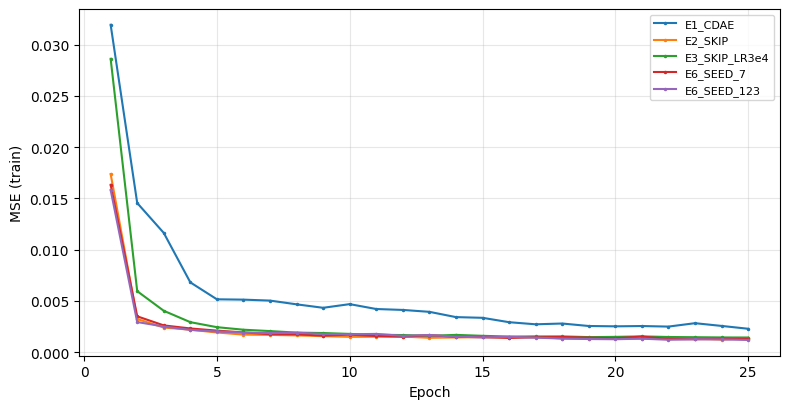

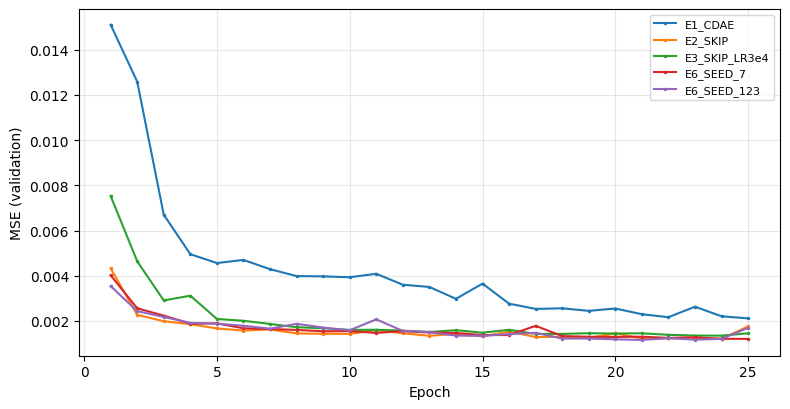

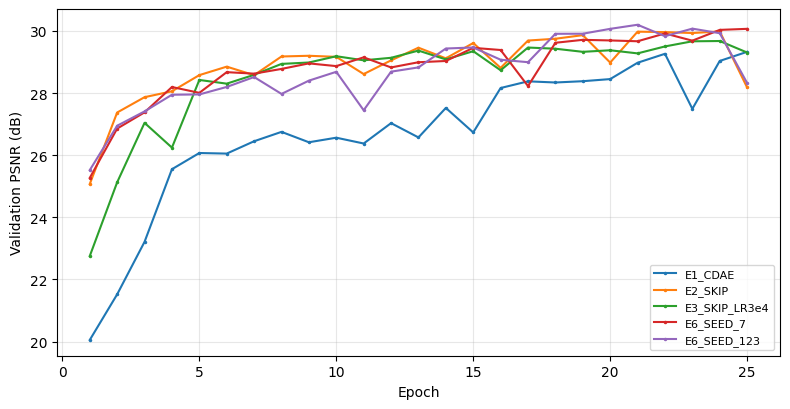

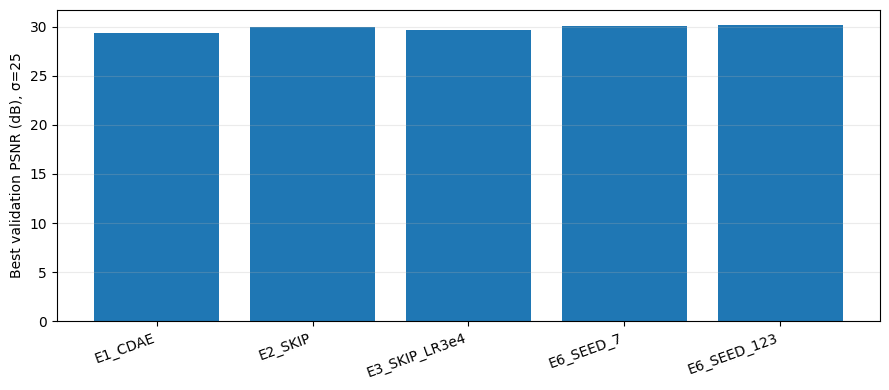

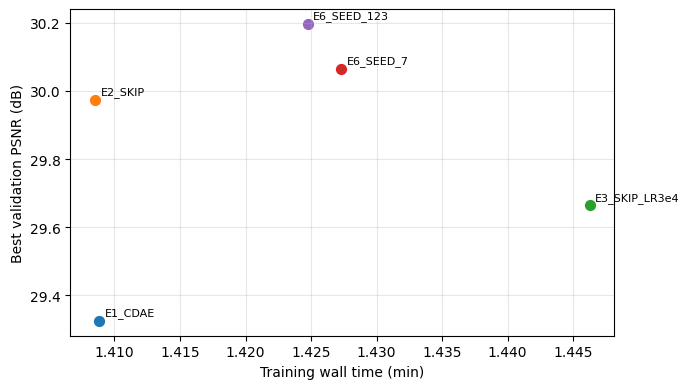

Графіки збережено: /kaggle/working/denoising_autoencoder/figures


In [26]:
fig_dir=OUTPUT/'figures'

def save_figure(name):
    plt.tight_layout(); plt.savefig(fig_dir/name,dpi=150,bbox_inches='tight')
    plt.show(); plt.close()

for value,ylabel,filename in [
    ('train_loss','MSE (train)','train_loss.png'),
    ('val_loss','MSE (validation)','validation_loss.png'),
    ('val_psnr_db','Validation PSNR (dB)','validation_psnr.png')]:
    plt.figure(figsize=(8,4.2))
    for r in RUNS:
        h=pd.read_csv(OUTPUT/'runs'/r['run_id']/'history.csv')
        plt.plot(h['epoch'],h[value],label=r['run_id'],marker='.',markersize=3)
    plt.xlabel('Epoch'); plt.ylabel(ylabel); plt.grid(alpha=.3); plt.legend(fontsize=8)
    save_figure(filename)

results_df=pd.DataFrame(RUNS)
plt.figure(figsize=(9,4))
plt.bar(results_df['run_id'],results_df['best_val_psnr_db'])
plt.ylabel('Best validation PSNR (dB), σ=25')
plt.xticks(rotation=20,ha='right'); plt.grid(axis='y',alpha=.25)
save_figure('architecture_comparison_val.png')

plt.figure(figsize=(7,4))
for _,r in results_df.iterrows():
    plt.scatter(r['total_minutes'],r['best_val_psnr_db'],s=50)
    plt.annotate(r['run_id'],(r['total_minutes'],r['best_val_psnr_db']),xytext=(4,4),textcoords='offset points',fontsize=8)
plt.xlabel('Training wall time (min)'); plt.ylabel('Best validation PSNR (dB)'); plt.grid(alpha=.3)
save_figure('quality_vs_gpu_time.png')

print('Графіки збережено:',fig_dir)

## Дослідження стабільності навчання

Для оцінки стабільності Skip-CDAE навчено тричі з різними значеннями seed: 42, 7 і 123. Усі інші параметри залишилися однаковими. Найкращий validation PSNR становив 29,9746, 30,0654 і 30,1966 dB відповідно.

Середнє значення PSNR — 30,0789 dB, вибіркове стандартне відхилення — 0,1116 dB. Різниця між крайніми значеннями становить 0,2221 dB. Отримані результати показують, що за трьох перевірених запусків якість моделі змінювалася незначно. При цьому оптимальна епоха відрізнялася: 21 для seeds 42 і 123 та 25 для seed 7.

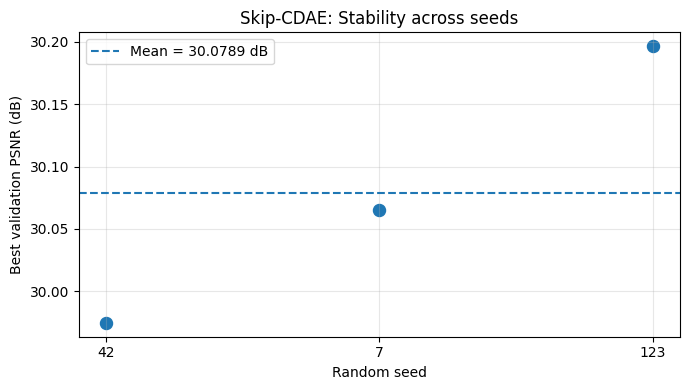

In [24]:

import matplotlib.pyplot as plt

stability = pd.read_csv(OUTPUT / 'stability_val.csv')

fig, ax = plt.subplots(figsize=(7, 4))

ax.scatter(
    stability['seed'].astype(str),
    stability['best_val_psnr_db'],
    s=75
)

mean_psnr = stability['best_val_psnr_db'].mean()
std_psnr = stability['best_val_psnr_db'].std(ddof=1)

ax.axhline(
    mean_psnr,
    linestyle='--',
    label=f'Mean = {mean_psnr:.4f} dB'
)

ax.set_title('Skip-CDAE: Stability across seeds')
ax.set_xlabel('Random seed')
ax.set_ylabel('Best validation PSNR (dB)')
ax.grid(alpha=0.3)
ax.legend()

fig.tight_layout()

fig_dir = OUTPUT / 'figures'
fig_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(fig_dir / 'stability.png', dpi=160)
plt.show()
plt.close(fig)


## 12. Фінальний тест

Після вибору моделі перевіряємо її на 100 фотографіях `DIV2K_valid_HR`, які не брали участі в навчанні або підборі параметрів. Для кожної фотографії створюємо шум із $\sigma\in\{15,25,50\}$ та порівнюємо зашумлене зображення, Gaussian Blur і автоенкодер.

Метрики рахуємо на повнорозмірних фотографіях. Якщо повне зображення не поміститься у відеопам'ять, використовується обробка частинами з перекриттям.

In [16]:
assert (OUTPUT/'MODEL_SELECTION.md').exists()

def load_selected_model(selection):
    # Завантаження checkpoint із безпечним режимом, якщо він підтримується.
    try:
        payload=torch.load(selection['checkpoint'],map_location='cpu',weights_only=True)
    except TypeError:
        payload=torch.load(selection['checkpoint'],map_location='cpu')
    model=build_model(selection['model']).to(DEVICE)
    model.load_state_dict(payload['model']); model.eval()
    return model

def infer_tiled(model,noisy,core=384,halo=32):
    """GPU tiles з overlap контекстом; core/halo кратні 4."""
    h,w=noisy.shape[-2:]
    result=torch.empty_like(noisy)
    for top in range(0,h,core):
        for left in range(0,w,core):
            bottom=min(top+core,h);right=min(left+core,w)
            y0=max(0,top-halo); x0=max(0,left-halo)
            y1=min(h,bottom+halo);x1=min(w,right+halo)
            tile=noisy[...,y0:y1,x0:x1]
            with torch.inference_mode(),torch.autocast('cuda',dtype=torch.float16,enabled=AMP):
                restored=model(tile)
            result[...,top:bottom,left:right]=restored[...,top-y0:bottom-y0,left-x0:right-x0]
    return result

@torch.inference_mode()
def restore_full(model,noisy_np):
    x=torch.from_numpy(np.ascontiguousarray(noisy_np.transpose(2,0,1))).unsqueeze(0).to(DEVICE)
    torch.cuda.synchronize()
    t0=time.perf_counter(); tiled=False
    try:
        with torch.autocast('cuda',dtype=torch.float16,enabled=AMP):
            y=model(x)
    except torch.cuda.OutOfMemoryError:
        torch.cuda.empty_cache()
        y=infer_tiled(model,x); tiled=True
    torch.cuda.synchronize()
    ms=(time.perf_counter()-t0)*1000
    result=y.squeeze(0).float().cpu().permute(1,2,0).numpy()
    return np.clip(result,0,1),ms,tiled


def make_test_noise(clean,sigma,image_id):
    # Один і той самий шум для всіх методів.
    seed=20262026+int(image_id)*1009+int(sigma)*1000003
    rng=np.random.default_rng(seed)
    noise=rng.normal(0,sigma/255.0,clean.shape).astype(np.float32)
    return np.clip(clean+noise,0,1),seed

# Перевірка tiled inference на штучному зображенні.
_test_model=CDAE(skip=True).to(DEVICE).eval()
_small=torch.rand(1,3,101,157,device=DEVICE)
with torch.inference_mode():
    full=_test_model(_small)
    tiled=infer_tiled(_test_model,_small,core=64,halo=32)
    diff=float((full-tiled).abs().max().item())
    assert np.isfinite(diff) and diff<0.08, f'Tiling check failed: {diff}'
print(f'Tiled inference sanity: max abs diff {diff:.6f} (small synthetic image)')
del _test_model,_small,full,tiled

test_rows=[]; visual_examples=[]
if RUN_FINAL_TEST:
    model=load_selected_model(winner)
    model.eval()
    with torch.inference_mode():
        for _ in range(3):
            with torch.autocast('cuda',dtype=torch.float16,enabled=AMP):
                model(torch.zeros(1,3,256,256,device=DEVICE))
    torch.cuda.synchronize()
    for p in tqdm(test_paths,desc='Held-out full-resolution test'):
        clean=load_rgb(p).astype(np.float32)/255.0
        for sigma in TEST_SIGMAS:
            noisy,noise_seed=make_test_noise(clean,sigma,p.stem)
            blur_start=time.perf_counter()
            filtered=gaussian_filter(noisy,blur_best['kernel'],blur_best['sigma'])
            blur_ms=(time.perf_counter()-blur_start)*1000
            restored,ms,tiled=restore_full(model,noisy)
            for method,arr,elapsed in [('Noisy',noisy,0.0),('GaussianBlur',filtered,blur_ms),
                                        (winner['run_id'],restored,ms)]:
                rec={'method':method,'image_id':p.stem,'sigma_255':sigma,
                     'noise_seed':noise_seed,'inference_ms':elapsed,
                     'height':clean.shape[0],'width':clean.shape[1],
                     'tiled':tiled if method==winner['run_id'] else False}
                rec.update(image_metrics(arr,clean))
                test_rows.append(rec)
            if sigma==25 and len(visual_examples)<8:
                visual_examples.append((p.stem,clean.copy(),noisy.copy(),filtered.copy(),restored.copy()))
        # Записуємо таблицю після кожної фотографії.
        pd.DataFrame(test_rows).to_csv(OUTPUT/'test_per_image.csv',index=False)
    del model
    print('Held-out test завершено, кількість записів:',len(test_rows))
else:
    print('Фінальне тестування SKIPPED. Результати test відсутні.')

Tiled inference sanity: max abs diff 0.000278 (small synthetic image)


Held-out full-resolution test:   0%|          | 0/100 [00:00<?, ?it/s]

Held-out test завершено, кількість записів: 900


## 13. Аналіз тестових результатів

У підсумковій таблиці показуємо середні PSNR і SSIM за фотографіями для кожного рівня шуму. Окремо розраховуємо приріст відносно зашумленого входу.

Для наочного порівняння будуємо приклади відновлення, карти абсолютної помилки та добірку фотографій із найбільшим і найменшим приростом PSNR.

,method,sigma_255,images,psnr_mean_db,psnr_std_db,psnr_median_db,ssim_mean,ssim_std,mse_mean,mae_mean,inference_ms_mean,delta_psnr_vs_noisy_db,delta_ssim_vs_noisy
0,E2_SKIP,15,100,31.3290,2.1620,31.6077,0.8610,0.0407,0.0008,0.0205,465.2948,6.3996,0.3451
1,E2_SKIP,25,100,29.6143,1.7880,29.8469,0.7908,0.0508,0.0012,0.0252,118.0709,8.9156,0.4410
2,E2_SKIP,50,100,23.9757,0.7578,23.9158,0.5314,0.0896,0.0041,0.0500,118.9407,8.7513,0.3531
3,GaussianBlur,15,100,28.4512,3.4057,28.5762,0.7884,0.0703,0.0020,0.0269,23.5541,3.5219,0.2725
4,GaussianBlur,25,100,27.0837,2.6618,27.1602,0.7025,0.0666,0.0024,0.0332,23.7368,6.3850,0.3527
5,GaussianBlur,50,100,23.6948,1.5643,24.0934,0.5168,0.0659,0.0046,0.0521,23.2431,8.4704,0.3386
6,Noisy,15,100,24.9293,0.3268,24.8220,0.5159,0.1176,0.0032,0.0448,0.0000,0.0000,0.0000
7,Noisy,25,100,20.6987,0.3901,20.6291,0.3498,0.1137,0.0085,0.0729,0.0000,0.0000,0.0000
8,Noisy,50,100,15.2244,0.4352,15.2033,0.1783,0.0799,0.0302,0.1361,0.0000,0.0000,0.0000


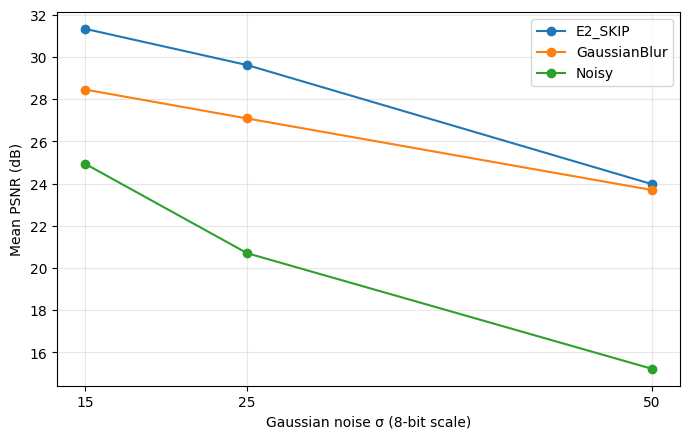

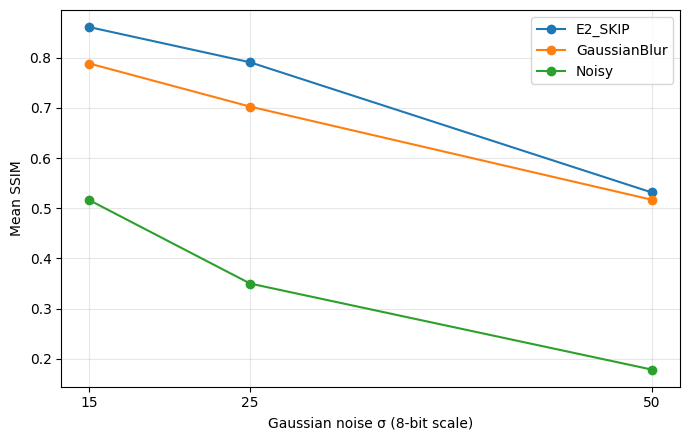

/tmp/ipykernel_50/3228542307.py:31: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([grouped[grouped.method==m][metric].values for m in methods],labels=methods)


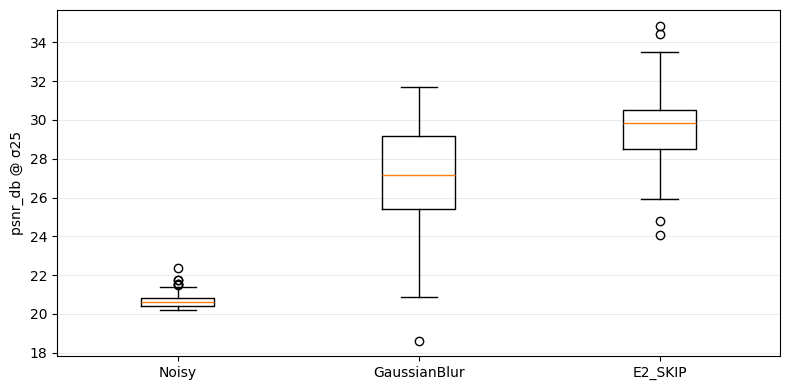

/tmp/ipykernel_50/3228542307.py:31: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([grouped[grouped.method==m][metric].values for m in methods],labels=methods)


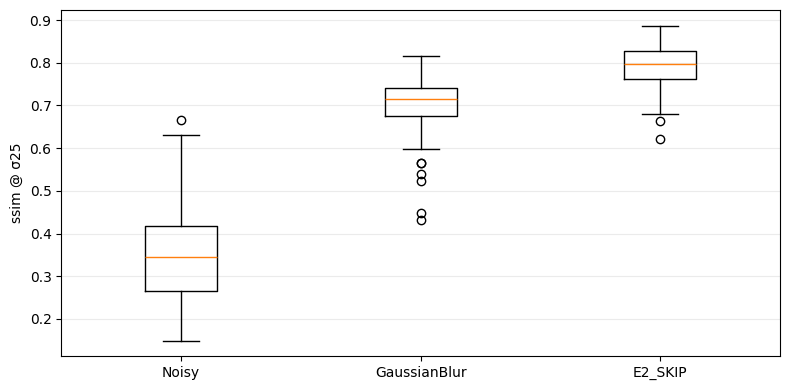

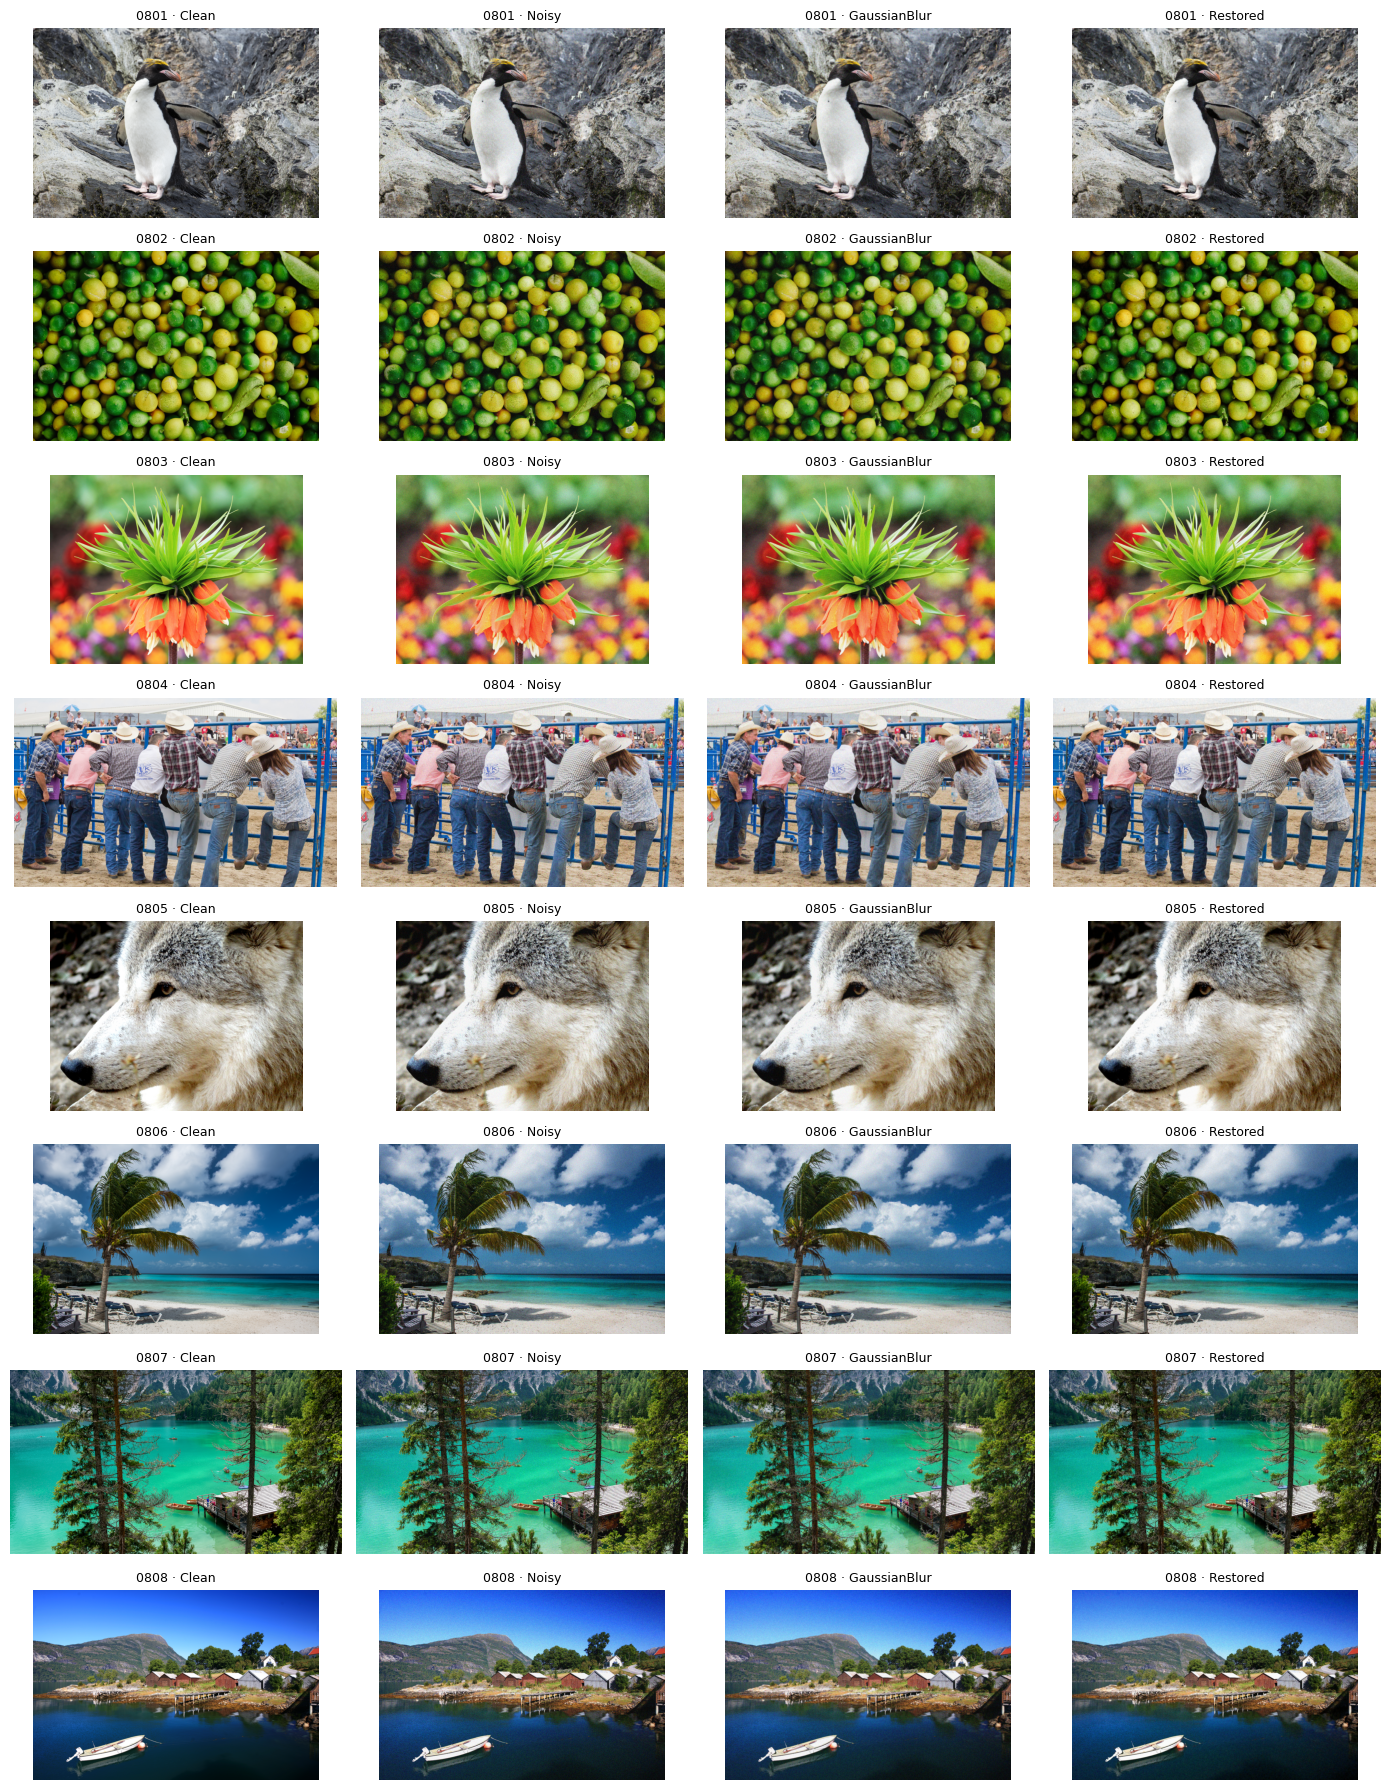

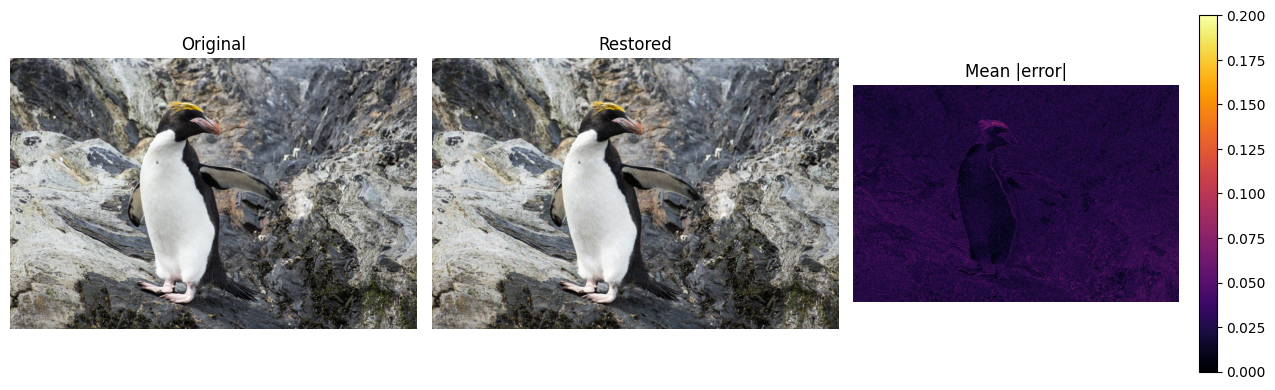

method,gain_db
image_id,
0828,3.304862
0807,3.310557
0856,5.159653
0876,5.255691
0895,5.490006


method,gain_db
image_id,
0877,12.240140
0868,12.292167
0844,12.421514
0896,13.046898
0843,13.074551


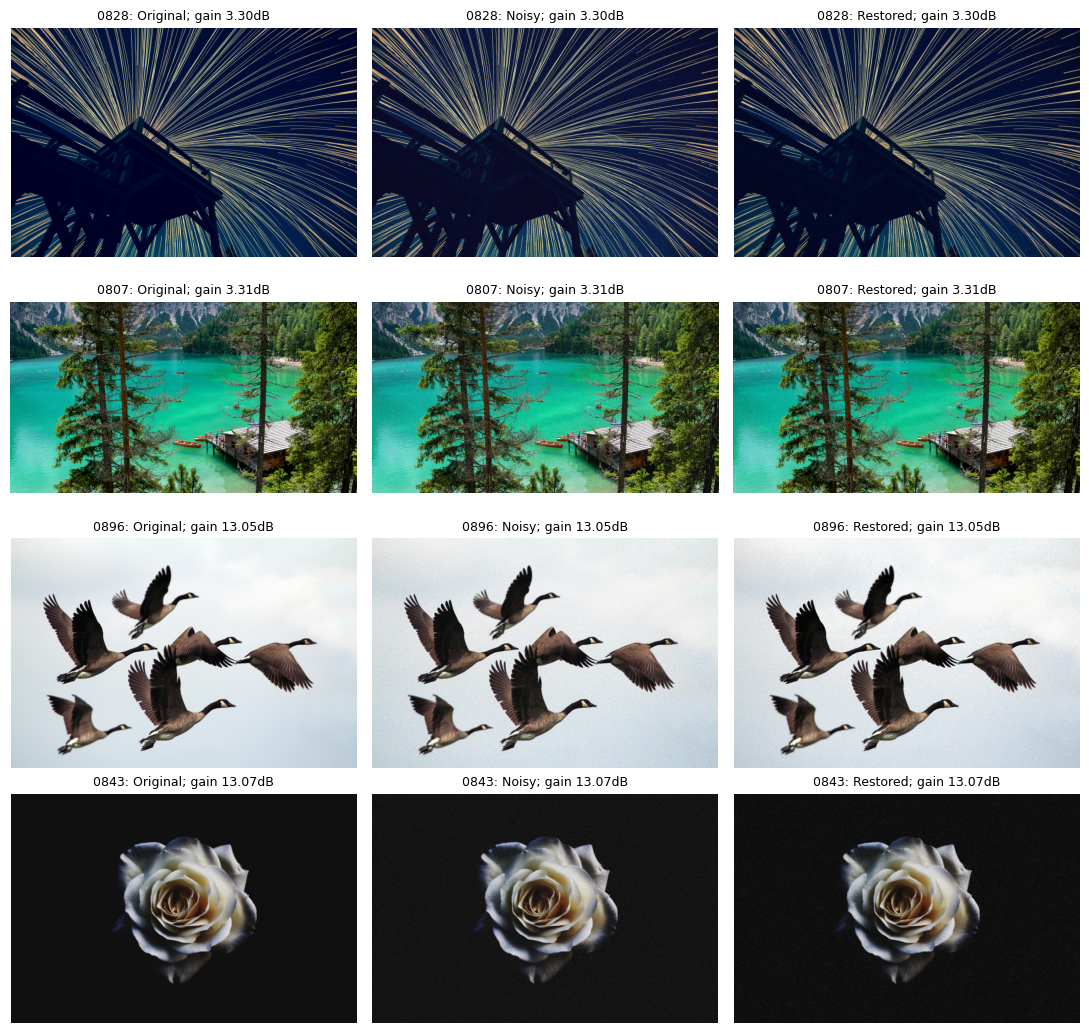

In [17]:
if test_rows:
    test_df=pd.DataFrame(test_rows)
    summary=test_df.groupby(['method','sigma_255'],as_index=False).agg(
        images=('image_id','nunique'), psnr_mean_db=('psnr_db','mean'),
        psnr_std_db=('psnr_db','std'),psnr_median_db=('psnr_db','median'),
        ssim_mean=('ssim','mean'),ssim_std=('ssim','std'),
        mse_mean=('mse','mean'),mae_mean=('mae','mean'),
        inference_ms_mean=('inference_ms','mean'))
    noisy_ref=summary[summary.method=='Noisy'].set_index('sigma_255')
    summary['delta_psnr_vs_noisy_db']=summary.apply(
        lambda r:r.psnr_mean_db-float(noisy_ref.loc[r.sigma_255,'psnr_mean_db']),axis=1)
    summary['delta_ssim_vs_noisy']=summary.apply(
        lambda r:r.ssim_mean-float(noisy_ref.loc[r.sigma_255,'ssim_mean']),axis=1)
    summary.to_csv(OUTPUT/'test_summary.csv',index=False)
    display(summary.round(4))

    for metric,ylabel,filename in [('psnr_mean_db','Mean PSNR (dB)','quality_vs_noise_psnr.png'),
                                    ('ssim_mean','Mean SSIM','quality_vs_noise_ssim.png')]:
        plt.figure(figsize=(7,4.5))
        for method,g in summary.groupby('method'):
            g=g.sort_values('sigma_255')
            plt.plot(g['sigma_255'],g[metric],marker='o',label=method)
        plt.xticks(TEST_SIGMAS);plt.xlabel('Gaussian noise σ (8-bit scale)')
        plt.ylabel(ylabel);plt.legend();plt.grid(alpha=.3)
        save_figure(filename)

    for metric,name in [('psnr_db','test_psnr_distribution.png'),('ssim','test_ssim_distribution.png')]:
        plt.figure(figsize=(8,4))
        grouped=test_df[test_df.sigma_255==25]
        methods=['Noisy','GaussianBlur',winner['run_id']]
        plt.boxplot([grouped[grouped.method==m][metric].values for m in methods],labels=methods)
        plt.ylabel(metric+' @ σ25');plt.grid(axis='y',alpha=.25)
        save_figure(name)

    n=len(visual_examples)
    fig,axes=plt.subplots(n,4,figsize=(14,max(2.5,n*2.25)))
    if n==1: axes=np.expand_dims(axes,0)
    for i,(image_id,clean,noisy,filtered,restored) in enumerate(visual_examples):
        for j,(label,img) in enumerate([('Clean',clean),('Noisy',noisy),('GaussianBlur',filtered),('Restored',restored)]):
            # Зменшення застосовується лише для показу, не для метрик.
            axes[i,j].imshow(img); axes[i,j].set_title(f'{image_id} · {label}',fontsize=9)
            axes[i,j].axis('off')
    save_figure('reconstruction_grid.png')

    # Карта помилки для одного прикладу.
    image_id,clean,noisy,filtered,restored=visual_examples[0]
    err=np.abs(clean-restored).mean(axis=2)
    fig,axes=plt.subplots(1,3,figsize=(13,4))
    axes[0].imshow(clean);axes[0].set_title('Original')
    axes[1].imshow(restored);axes[1].set_title('Restored')
    im=axes[2].imshow(err,cmap='inferno',vmin=0,vmax=0.20)
    axes[2].set_title('Mean |error|');fig.colorbar(im,ax=axes[2])
    for ax in axes: ax.axis('off')
    save_figure('error_map.png')

    # Найкращі та найгірші приклади за приростом PSNR при σ=25.
    df25=test_df[test_df.sigma_255==25]
    wide=df25.pivot(index='image_id',columns='method',values='psnr_db')
    wide['gain_db']=wide[winner['run_id']]-wide['Noisy']
    wide=wide.sort_values('gain_db')
    pd.concat([wide.head(10).assign(group='worst_gain'),
               wide.tail(10).assign(group='best_gain')]).to_csv(OUTPUT/'best_worst_images.csv')
    display(wide[['gain_db']].head(5),wide[['gain_db']].tail(5))
    selected_ids=list(wide.head(2).index)+list(wide.tail(2).index)
    by_id={p.stem:p for p in test_paths}
    selected_model=load_selected_model(winner)
    fig,axes=plt.subplots(len(selected_ids),3,figsize=(11,len(selected_ids)*2.6))
    for i,image_id in enumerate(selected_ids):
        original=load_rgb(by_id[image_id]).astype(np.float32)/255
        noisy,_=make_test_noise(original,25,image_id)
        restored,_,_=restore_full(selected_model,noisy)
        for j,(label,img) in enumerate([('Original',original),('Noisy',noisy),('Restored',restored)]):
            axes[i,j].imshow(img);axes[i,j].axis('off')
            axes[i,j].set_title(f'{image_id}: {label}; gain {wide.loc[image_id,"gain_db"]:.2f}dB',fontsize=9)
    save_figure('best_worst_examples.png')
    del selected_model
else:
    print('Немає тестових даних — не створюємо фіктивних рисунків або таблиць.')

## 14. Файли для звіту та захисту

На основі отриманих CSV і конфігурацій створюються технічний звіт, журнал запусків, короткий текст для усного захисту та README. У цих файлах будуть лише результати, розраховані під час виконання Notebook; посилання на GitHub потрібно буде додати після публікації репозиторію.

In [29]:
def fmt(v,nd=3):
    return f'{v:.{nd}f}' if v is not None and np.isfinite(v) else 'N/A'

def markdown_table(df, cols=None, precision=3):
    if cols is not None: df=df[cols]
    fields=[str(c) for c in df.columns]
    rows=[]
    for row in df.itertuples(index=False,name=None):
        rows.append([fmt(v,precision) if isinstance(v,(float,np.floating)) else str(v) for v in row])
    return '\n'.join(['| '+' | '.join(fields)+' |',
                      '| '+' | '.join(['---']*len(fields))+' |']+
                     ['| '+' | '.join(row)+' |' for row in rows])

run_df=pd.DataFrame(RUNS)
exp_cols=['run_id','model','seed','crop','lr','trained_epochs','best_epoch',
          'best_val_psnr_db','best_val_ssim','total_minutes','gpu_peak_mb']
report_runs = run_df.copy()
report_runs['lr'] = report_runs['lr'].map(lambda lr: f'{lr:.4g}')
exp_table = markdown_table(report_runs, exp_cols)
test_table=(markdown_table(summary,['method','sigma_255','images','psnr_mean_db',
                                    'psnr_std_db','ssim_mean','delta_psnr_vs_noisy_db'])
            if test_rows else 'Фінальне тестування не виконано.')
training_minutes=float(run_df.total_minutes.sum())
by_id = run_df.set_index('run_id')
e1 = by_id.loc['E1_CDAE']
e2 = by_id.loc['E2_SKIP']

report=f"""# Технічний звіт

## Мета роботи
Навчити згортковий автоенкодер відновлювати RGB-фотографії із синтетичним гаусівським шумом і порівняти його з простим фільтром та модифікацією зі skip connections.

Шум задається як `y = clip(x + N(0, (σ/255)²), 0, 1)`. Модель передбачає `x_hat = fθ(y)`, а функція втрат — MSE між відновленим і чистим зображенням. Якість оцінюється за PSNR та SSIM (`data_range=1.0`).

## Набір даних
Використано HR-фотографії DIV2K. Із 800 навчальних зображень виділено 720 для train та 80 для внутрішньої валідації; 100 з офіційного набору `DIV2K_valid_HR` залишено для нашого фінального тесту. Це власний поділ, не офіційний DIV2K challenge test.

Seed поділу: {SEED}. SHA256 списків зображень: `{split_hash}`. Навчальні фрагменти мають розмір {PATCH_SIZE}×{PATCH_SIZE}, за винятком експериментів із 128×128. Для train шум генерується заново, а для val/test він фіксований. Ідентифікатори зображень у вибірках не перетинаються.

## Моделі й навчання
Порівняно CDAE та Skip-CDAE. Обидві мережі мають два етапи зменшення роздільності та декодер із bilinear upsampling. Skip-CDAE також передає проміжні ознаки з енкодера до декодера.

Навчання виконано в PyTorch на {GPU_NAME}: оптимізатор Adam, MSE loss, AMP={AMP}, кешування RGB у RAM={USE_RAM_CACHE}. Найкращі ваги зберігалися за внутрішнім validation PSNR при σ=25. Було налаштовано Early Stopping із patience={PATIENCE}, але жоден із п'яти запусків не зупинився раніше: усі виконали 25 епох.

## Результати навчальних експериментів
{exp_table}
Сумарний час навчання: {training_minutes:.2f} хв (без підготовки даних і фінального тестування).

Для фінального тестування обрано модель {winner['run_id']} за результатами основних експериментів E1–E3. Вона досягла validation PSNR {winner['best_val_psnr_db']:.3f} dB на епосі {winner['best_epoch']}. Повтори E6 проведено для аналізу стабільності. Вони не змінюють попередній вибір фінальної моделі.

Порівняння архітектур показало, що Skip-CDAE (E2) отримала вищий PSNR, ніж звичайний CDAE (E1): {e2['best_val_psnr_db']:.3f} проти {e1['best_val_psnr_db']:.3f} dB. Водночас за SSIM результат E1 був кращим: {e1['best_val_ssim']:.3f} проти {e2['best_val_ssim']:.3f}. Отже, skip connections покращили PSNR, але не забезпечили одночасного покращення всіх метрик. Модель E2 обрана за заздалегідь визначеним критерієм PSNR.

Для Gaussian Blur на внутрішній валідації обрано kernel={blur_best['kernel']}, sigma={blur_best['sigma']}.

## Фінальна оцінка
{test_table}

## Графіки й аналіз
Криві навчання збережено в `figures/train_loss.png`, `figures/validation_loss.png` і `figures/validation_psnr.png`. Співвідношення якості та часу наведено в `figures/quality_vs_gpu_time.png`. Значення окремих епох можна перевірити у файлах `runs/<run_id>/history.csv`.

Train loss поступово зменшувався протягом навчання. Найпомітніше покращення валідаційних метрик відбувалося на початкових епохах, після чого прогрес уповільнився. Для E2 найкращий validation PSNR отримано на 21-й епосі. Наприкінці навчання спостерігалися коливання валідаційної якості, тому для тестування використано найкращий checkpoint, а не ваги останньої епохи.

## Обмеження
Навчання проводилося на синтетичному AWGN, тому результат не можна автоматично переносити на шум реальної камери. Автоенкодер також може згладжувати тонкі текстури. PSNR оцінює помилку пікселів і не повністю описує візуальну якість. На сильному шумі σ=50 перевага Skip-CDAE над Gaussian Blur зменшилася до 0.281 dB за середнім PSNR. Отже, модель, навчена на σ=25, гірше зберігає свою перевагу над класичним методом за значно вищого рівня шуму.

Числа з інших публікацій можна безпосередньо порівнювати лише за однакових даних, параметрів шуму та способу оцінювання. Через AMP і `cudnn.benchmark` запуск не гарантує повної бітової відтворюваності на іншому обладнанні.

## Джерела
- DIV2K: https://data.vision.ee.ethz.ch/cvl/DIV2K/
- Vincent et al. (2008): https://www.cs.toronto.edu/~larocheh/publications/icml-2008-denoising-autoencoders.pdf
- Ronneberger et al. (2015), U-Net: https://arxiv.org/abs/1505.04597
- PyTorch AMP: https://docs.pytorch.org/docs/stable/amp.html
- scikit-image metrics: https://scikit-image.org/docs/stable/api/skimage.metrics.html

Посилання на GitHub: додати після публікації репозиторію.
"""
(OUTPUT/'report.md').write_text(report,encoding='utf-8')

status_lines=['# Журнал експериментів','',f'GPU: {GPU_NAME}',f'Split: {split_hash}','']
for r in RUNS:
    status_lines += [f"## {r['run_id']}",'- Status: COMPLETED',
        f"- Config: runs/{r['run_id']}/config.json",f"- Parameters: {r['trainable_parameters']}",
        f"- Epochs: {r['trained_epochs']}; steps: {r['optimizer_steps']}",
        f"- Best val PSNR: {r['best_val_psnr_db']:.4f} dB, best SSIM {r['best_val_ssim']:.4f}, epoch {r['best_epoch']}",
        f"- Time: {r['total_minutes']:.2f} min; peak GPU memory: {r['gpu_peak_mb']:.0f} MB",
        f"- Evidence: runs/{r['run_id']}/history.csv, best.pt, last.pt",'']
(OUTPUT/'EXPERIMENT_LOG.md').write_text('\n'.join(status_lines),encoding='utf-8')
(OUTPUT/'PROGRESS.md').write_text(
    f'# Хід роботи\n\n- Основні експерименти: COMPLETED ({len(RUNS)} runs)\n'
    f'- Фінальний тест: {"COMPLETED" if test_rows else "SKIPPED"}\n'
    f'- Обраний запуск: {winner["run_id"]}\n- GPU: {GPU_NAME}\n'
    f'- Додаткові E4/E5: {"REQUESTED" if RUN_EXTENDED else "SKIPPED"}\n'
    f'- Повтори з іншими seeds: {"REQUESTED" if RUN_STABILITY else "SKIPPED"}\n',encoding='utf-8')

sigma25_gain=(summary[(summary.method==winner['run_id'])&(summary.sigma_255==25)]
              ['delta_psnr_vs_noisy_db'].iloc[0] if test_rows else None)

defense=f"""# Текст для захисту

Мета моєї роботи — відновлювати кольорові зображення, до яких додано гаусівський шум, за допомогою згорткового автоенкодера.

Для навчання використано фотографії DIV2K. Із 800 зображень для навчання 720 пішли в train, ще 80 — у validation. Окремі 100 фотографій з офіційного validation-набору я залишила для фінального тесту. Мережа навчається на випадкових фрагментах, до яких щоразу додається новий шум. Для валідації приклади та шум не змінюються.

Порівнювалися два варіанти автоенкодера: звичайний CDAE і Skip-CDAE зі зв'язками між рівнями енкодера та декодера. Функція втрат — MSE, оптимізатор — Adam. Окремо перевірено вплив learning rate. Навчання виконувалося на GPU {GPU_NAME} зі змішаною точністю; RGB-зображення кешувалися в оперативній пам'яті.

Найкращий результат на внутрішній валідації при σ=25 отримав запуск {winner['run_id']}: {winner['best_val_psnr_db']:.3f} dB, епоха {winner['best_epoch']}. Порівняння моделей є в `experiments.csv`, а криві навчання — у папці `figures`.

""" + (f'На фінальному тесті при σ=25 модель покращила PSNR відносно зашумленого входу на {sigma25_gain:.3f} dB. Для порівняння використані ті самі фотографії та реалізації шуму для Noisy, GaussianBlur і автоенкодера.\n\n'
         if sigma25_gain is not None else 'Фінальний тест ще не виконувався; тестових метрик поки немає.\n\n') + """На демонстрації покажу графіки train і validation loss, таблиці PSNR/SSIM та кілька прикладів очищення фотографій. Також відкрию конфігурацію й ваги обраного запуску. Основне обмеження роботи — навчання на штучному гаусівському шумі; для реальних фотографій із камери якість може бути іншою.
"""
(OUTPUT/'defense_script.md').write_text(defense,encoding='utf-8')

README=f"""# Denoising Autoencoder — Kaggle

Навчання та тестування виконуються в Notebook. Вхідні дані — HR-зображення DIV2K (800 train, 100 valid). У роботі використано власний поділ 720/80/100.

- GPU: {GPU_NAME}; AMP: {AMP}
- Конфігурації: `runs/<run_id>/config.json`
- Ваги моделей: `runs/<run_id>/best.pt`, `last.pt`
- Історія навчання: `runs/<run_id>/history.csv`
- Зведення експериментів: `experiments.csv`
- Фінальні метрики: `test_summary.csv`, `test_per_image.csv` (якщо тест запускався)
- Рисунки: `figures/*.png`
- Рішення про вибір моделі: `MODEL_SELECTION.md`
- Звіт і текст захисту: `report.md`, `defense_script.md`
- Журнали: `DECISIONS.md`, `EXPERIMENT_LOG.md`, `PROGRESS.md`

Для повторення експериментів збережено seeds, параметри запусків і списки фотографій. Абсолютно однакові результати на різному GPU не гарантовані. Чисті фотографії для навчання беруться з DIV2K; результати й ваги формуються під час виконання Notebook.

Джерело даних: https://data.vision.ee.ethz.ch/cvl/DIV2K/
"""
(OUTPUT/'README.md').write_text(README,encoding='utf-8')

# У ZIP додаємо лише невеликі результати та документацію.
package=OUTPUT.parent/'denoising_autoencoder_report_bundle.zip'
with zipfile.ZipFile(package,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for p in OUTPUT.rglob('*'):
        if p.is_file() and p.suffix.lower() not in ('.pt','.tmp') and 'unpacked' not in p.parts:
            z.write(p,p.relative_to(OUTPUT.parent))
print('Звіт, таблиці, рисунки та журнали:',OUTPUT)
print('Архів без ваг моделей:',package)
print('Файл обраної моделі:', winner['checkpoint'])

Звіт, таблиці, рисунки та журнали: /kaggle/working/denoising_autoencoder
Архів без ваг моделей: /kaggle/working/denoising_autoencoder_report_bundle.zip
Файл обраної моделі: /kaggle/working/denoising_autoencoder/runs/E2_SKIP/best.pt


## 15. Що зберегти після виконання

Для захисту знадобляться `experiments.csv`, графіки `validation_psnr.png` і `quality_vs_noise_psnr.png`, приклади `reconstruction_grid.png`, підсумкова таблиця тесту та `best.pt` обраної моделі. Короткий текст виступу записується у `defense_script.md`.

Вихідні файли лежать у `/kaggle/working/denoising_autoencoder`. Їх можна отримати через `Save Version` і вкладку `Output`. Окремий ZIP містить звіт, таблиці й рисунки без великих файлів ваг.

Якщо потрібен ширший аналіз, можна окремо запустити експерименти з іншими розмірами фрагментів (`RUN_EXTENDED`) або кількома random seeds (`RUN_STABILITY`). Результати цього проєкту стосуються власного поділу DIV2K і не є офіційними оцінками challenge.

In [30]:

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from IPython.display import FileLink, display
import pandas as pd
import os

df = pd.read_csv(OUTPUT / 'stability_val.csv')
scores = df['best_val_psnr_db']

mean = scores.mean()
std = scores.std(ddof=1)
spread = scores.max() - scores.min()

report_path = OUTPUT / 'report.md'
report = report_path.read_text(encoding='utf-8')



start = '<!-- stability:start -->'
end = '<!-- stability:end -->'

section = f"""
## Стабільність навчання

Для перевірки стабільності Skip-CDAE навчено з seeds 42, 7 і 123.
Архітектура, learning rate та кількість навчальних епох
залишалися однаковими.

Середній найкращий validation PSNR: {mean:.4f} dB.
Вибіркове стандартне відхилення: {std:.4f} dB.
Розмах значень: {spread:.4f} dB.

За трьох перевірених запусків результати були близькими.
Це свідчить про невеликий розкид валідаційної якості,
але не гарантує однакових результатів для всіх seeds.

Результати: `stability_val.csv`.
Графік: `figures/stability.png`.

Фінальний тест не використовувався для вибору моделі
під час цих повторних експериментів.
"""

if start in report and end in report:
    before = report.split(start)[0]
    after = report.split(end, 1)[1]
    report = before + start + section + end + after
else:
    report += '\n' + start + section + end + '\n'

report_path.write_text(report, encoding='utf-8')

progress_path = OUTPUT / 'PROGRESS.md'
if progress_path.exists():
    progress = progress_path.read_text(encoding='utf-8')
    progress = progress.replace(
        '- Повтори з іншими seeds: REQUESTED',
        '- Повтори з іншими seeds: COMPLETED (42, 7, 123)'
    )
    progress_path.write_text(progress, encoding='utf-8')

zip_path = OUTPUT.parent / 'denoising_autoencoder_full_results.zip'

with ZipFile(zip_path, 'w', ZIP_DEFLATED, compresslevel=6) as archive:
    for path in sorted(OUTPUT.rglob('*')):
        if not path.is_file():
            continue
        if 'unpacked' in path.relative_to(OUTPUT).parts:
            continue
        if path.suffix.lower() in ('.tmp', '.zip'):
            continue
        if path.suffix.lower() == '.pt' and path.name != 'best.pt':
            continue
        archive.write(path, path.relative_to(OUTPUT.parent))

with ZipFile(zip_path) as archive:
    assert archive.testzip() is None

print(f'Архів готовий: {zip_path.stat().st_size / 2**20:.1f} MB')

os.chdir(zip_path.parent)
display(FileLink(zip_path.name, result_html_prefix='Завантажити результати: '))


Архів готовий: 35.0 MB


/kaggle/working/denoising_autoencoder_full_results.zip